# Kernel SHAP

We train a sentiment classifier using word-presence features and explain its predictions with Kernel SHAP.

In [1]:
import re
import html
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)

SEED = 42
MAX_PER_CLASS = 20000
MAX_FEATURES = 250
BACKGROUND_SIZE = 10
N_EXPLAIN = 8
NSAMPLES = 200

np.random.seed(SEED)


## 1. Load the data

The CSV has no header. We only need the tweet text and sentiment label (`0` for negative, `4` for positive). Since the full dataset is large, we sample rows from each chunk rather than reading only the beginning of the file.

In [2]:
filename = "training.1600000.processed.noemoticon.csv"

# Kaggle input first, then a local copy if running in Jupyter.
paths = list(Path("/kaggle/input").rglob(filename)) if Path("/kaggle/input").exists() else []
paths += list(Path("data").rglob(filename)) if Path("data").exists() else []
if Path(filename).exists():
    paths.append(Path(filename))

if paths:
    csv_path = paths[0]
else:
    # Download the same Kaggle dataset if it has not been attached locally.
    import kagglehub
    folder = Path(kagglehub.dataset_download("kazanova/sentiment140"))
    csv_path = next(folder.rglob(filename))

print(csv_path)

columns = ["target", "id", "date", "query", "user", "text"]
parts = []
for i, chunk in enumerate(pd.read_csv(
    csv_path, header=None, names=columns, usecols=["target", "text"],
    encoding="latin-1", chunksize=100000
)):
    chunk = chunk[chunk["target"].isin([0, 4])].dropna()
    parts.append(chunk.sample(frac=0.10, random_state=SEED + i))

data = pd.concat(parts, ignore_index=True)
data = pd.concat([
    group.sample(n=min(len(group), MAX_PER_CLASS), random_state=SEED)
    for _, group in data.groupby("target")
], ignore_index=True)

data["label"] = (data["target"] == 4).astype(int)
print(data["label"].value_counts().rename(index={0: "negative", 1: "positive"}))
data[["text", "label"]].head()

Using Colab cache for faster access to the 'sentiment140' dataset.
/kaggle/input/sentiment140/training.1600000.processed.noemoticon.csv
label
negative    20000
positive    20000
Name: count, dtype: int64


,text,label
0,@_Freya What's the matter? Anything we can do ...,0
1,i miss my chicas already,0
2,@hawknelson Wish they had what? It trails off....,0
3,At the Bridge for daddy day! Missing the kiddo...,0
4,"@KayKay18 To be honest, I didn't look...sorry!",0


## 2. Clean tweets and prepare features

URLs and @mentions are removed. Hashtag words are kept, since they can carry sentiment. We use binary word features so that each column represents whether a word appears in a tweet.

In [3]:
def clean_tweet(text):
    text = html.unescape(str(text)).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return re.sub(r"\s+", " ", text).strip()


data["clean_text"] = data["text"].apply(clean_tweet)
data = data[data["clean_text"].str.len() > 2]
data = data.drop_duplicates(subset="clean_text").reset_index(drop=True)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    data["clean_text"], data["label"],
    test_size=0.2, random_state=SEED, stratify=data["label"]
)

vectorizer = CountVectorizer(
    binary=True,
    max_features=MAX_FEATURES,
    min_df=3,
    token_pattern=r"(?u)\b[a-z][a-z']+\b"
)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
feature_names = vectorizer.get_feature_names_out().tolist()

print("Training tweets:", X_train.shape[0])
print("Test tweets:", X_test.shape[0])
print("Features:", len(feature_names))

Training tweets: 31628
Test tweets: 7907
Features: 250


## 3. Train and evaluate the classifier

We use logistic regression with binary word features. The test scores measure the classifier's performance; they are separate from the SHAP explanation checks below.


Logistic Regression - Test Set
Accuracy:  0.7061
Precision: 0.6905
Recall:    0.7438
F1-score:  0.7162
ROC-AUC:   0.7752

Classification Report:
              precision    recall  f1-score   support

    Negative       0.72      0.67      0.70      3965
    Positive       0.69      0.74      0.72      3942

    accuracy                           0.71      7907
   macro avg       0.71      0.71      0.71      7907
weighted avg       0.71      0.71      0.71      7907



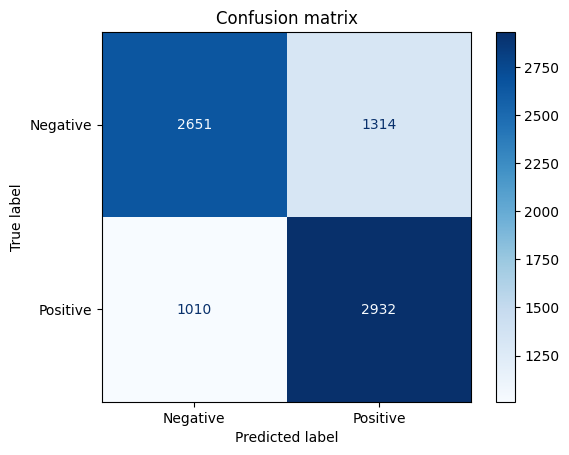

In [4]:
model = LogisticRegression(max_iter=1000, solver="liblinear", random_state=SEED)
model.fit(X_train, y_train)

pred = model.predict(X_test)
probs = model.predict_proba(X_test)[:, 1]

print("Logistic Regression - Test Set")
print(f"Accuracy:  {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, probs):.4f}")
print("\nClassification Report:")
print(classification_report(
    y_test, pred, target_names=["Negative", "Positive"], zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Negative", "Positive"], cmap="Blues"
)
plt.title("Confusion matrix")
plt.show()


## 4. Kernel SHAP

For a subset of features $S$, Kernel SHAP keeps the features in $S$ from the tweet being explained and fills in the others using background examples. It fits a locally weighted linear model

$$g(z')=\phi_0+\sum_{j=1}^{M}\phi_j z'_j,$$

where the weight assigned to a subset $S$ (for $0<|S|<M$) is

$$\pi(S)=\frac{M-1}{\binom{M}{|S|}|S|(M-|S|)}.$$

Here the explained output is $P(\text{positive})$. Positive SHAP values push this probability up; negative values push it down.

In [5]:
# KernelExplainer only needs a prediction function and background data.
def predict_positive(x):
    if isinstance(x, pd.DataFrame):
        x = x.to_numpy()
    return model.predict_proba(sparse.csr_matrix(x))[:, 1]


rng = np.random.default_rng(SEED)
bg_idx = rng.choice(X_train.shape[0], size=min(BACKGROUND_SIZE, X_train.shape[0]), replace=False)
background = pd.DataFrame(X_train[bg_idx].toarray(), columns=feature_names)

# Take an equal number of positive and negative tweets from the test split.
pos_idx = np.flatnonzero(y_test.to_numpy() == 1)
neg_idx = np.flatnonzero(y_test.to_numpy() == 0)
n_each = min(N_EXPLAIN // 2, len(pos_idx), len(neg_idx))
selected = np.r_[
    rng.choice(pos_idx, n_each, replace=False),
    rng.choice(neg_idx, n_each, replace=False)
]

X_explain = pd.DataFrame(X_test[selected].toarray(), columns=feature_names)
tweets = X_test_text.iloc[selected].reset_index(drop=True)
actual = y_test.iloc[selected].reset_index(drop=True)

pd.DataFrame({
    "tweet": tweets,
    "actual": actual.map({0: "negative", 1: "positive"}),
    "predicted P(positive)": predict_positive(X_explain)
})

,tweet,actual,predicted P(positive)
0,if it is anything that the community college f...,positive,0.707217
1,sup twittums?,positive,0.570450
2,i know. i love my parents very much and i don'...,positive,0.565789
3,i think that my lovely brother should take me ...,positive,0.715988
4,saturday classes are such a bummer,negative,0.555678
5,"going to the gym in 2mins, still got y headach...",negative,0.406677
6,"it is with extreme sadness that i removed ""ele...",negative,0.626937
7,my brother must hate me. he didn't answer his ...,negative,0.009345


In [6]:
explainer = shap.KernelExplainer(predict_positive, background, link="identity")
values = explainer.shap_values(
    X_explain,
    nsamples=NSAMPLES,
    l1_reg="num_features(15)",
    silent=True
)
shap_values = np.asarray(values)
base_value = float(explainer.expected_value)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(X_explain), base_value),
    data=X_explain.to_numpy(),
    feature_names=feature_names
)

print("SHAP values shape:", shap_values.shape)
print("Expected prediction:", round(base_value, 4))

SHAP values shape: (8, 250)
Expected prediction: 0.3671


## 5. Evaluate the SHAP explanations

The model score and the explanation should satisfy

$$f(x)\approx\phi_0+\sum_j\phi_j.$$

We compare the model probability with the reconstructed probability for each explained tweet. This checks additivity, not whether the word attributions are semantically correct.


In [7]:
model_probs = predict_positive(X_explain)
shap_probs = base_value + shap_values.sum(axis=1)
abs_error = np.abs(model_probs - shap_probs)

check = pd.DataFrame({
    "actual": actual.map({0: "Negative", 1: "Positive"}),
    "model P(positive)": model_probs,
    "base + SHAP": shap_probs,
    "absolute error": abs_error,
    "additivity check": np.isclose(model_probs, shap_probs, rtol=1e-5, atol=1e-6)
})
display(check.round(6))

print(f"Mean absolute reconstruction error: {abs_error.mean():.8f}")
print(f"Maximum reconstruction error:       {abs_error.max():.8f}")
print(f"Additivity checks passed:           {check['additivity check'].sum()}/{len(check)}")


,actual,model P(positive),base + SHAP,absolute error,additivity check
0,Positive,0.707217,0.707217,0.0,True
1,Positive,0.570450,0.570450,0.0,True
2,Positive,0.565789,0.565789,0.0,True
3,Positive,0.715988,0.715988,0.0,True
4,Negative,0.555678,0.555678,0.0,True
5,Negative,0.406677,0.406677,0.0,True
6,Negative,0.626937,0.626937,0.0,True
7,Negative,0.009345,0.009345,0.0,True


Mean absolute reconstruction error: 0.00000000
Maximum reconstruction error:       0.00000000
Additivity checks passed:           8/8


## 6. Explain individual tweets

The waterfall plots show how the word features move the probability away from its base value. Features are binary: `1` means the word is present and `0` means it is absent.



Tweet: if it is anything that the community college faculty association can help with, let me know!
Actual: Positive | Predicted: Positive
Model P(positive): 0.7072
Base value:        0.3671
Base + SHAP:       0.7072
Additivity check:  True


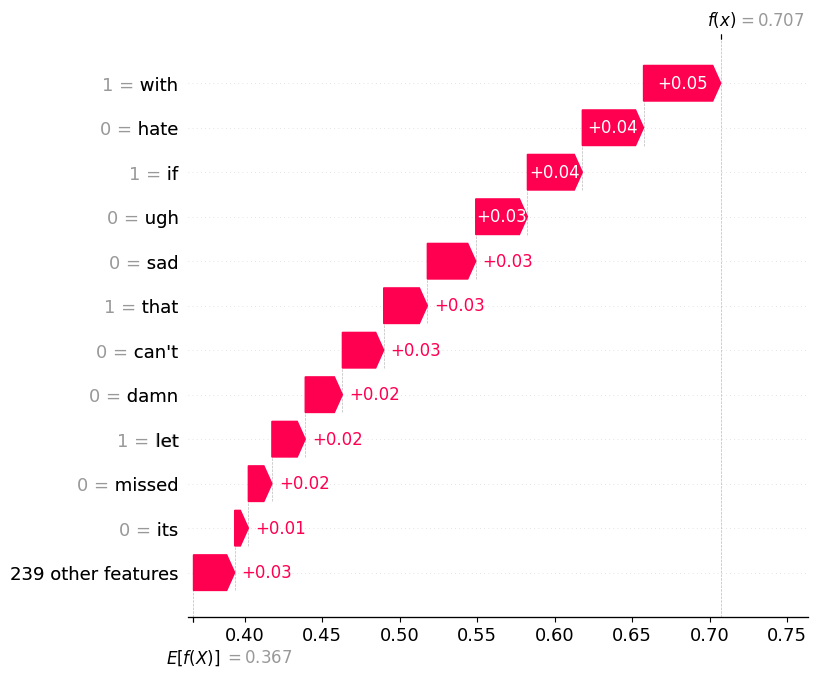


Tweet: saturday classes are such a bummer
Actual: Negative | Predicted: Positive
Model P(positive): 0.5557
Base value:        0.3671
Base + SHAP:       0.5557
Additivity check:  True


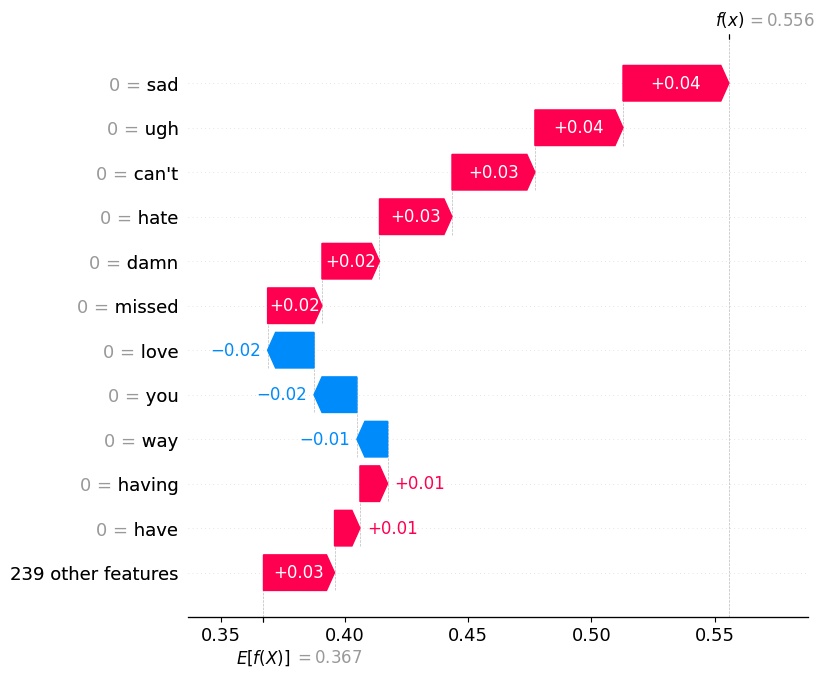

In [8]:
# One positive and one negative example from the selected test tweets.
for i in (0, n_each):
    label = "Positive" if actual.iloc[i] == 1 else "Negative"
    predicted = "Positive" if model_probs[i] >= 0.5 else "Negative"

    print("\nTweet:", tweets.iloc[i])
    print(f"Actual: {label} | Predicted: {predicted}")
    print(f"Model P(positive): {model_probs[i]:.4f}")
    print(f"Base value:        {base_value:.4f}")
    print(f"Base + SHAP:       {shap_probs[i]:.4f}")
    print(f"Additivity check:  {np.isclose(model_probs[i], shap_probs[i], rtol=1e-5, atol=1e-6)}")
    shap.plots.waterfall(explanation[i], max_display=12)


## 7. Feature importance

Mean absolute SHAP value gives the average size of a feature's contribution over the tweets explained here. Since this is a small test sample, the ranking should not be treated as a dataset-wide estimate.

,word,mean_abs_shap
0,hate,0.038829
1,sad,0.036290
2,ugh,0.030323
3,can't,0.028606
4,my,0.023319
5,love,0.022999
6,damn,0.015612
7,with,0.014154
8,missed,0.013077
9,still,0.012640


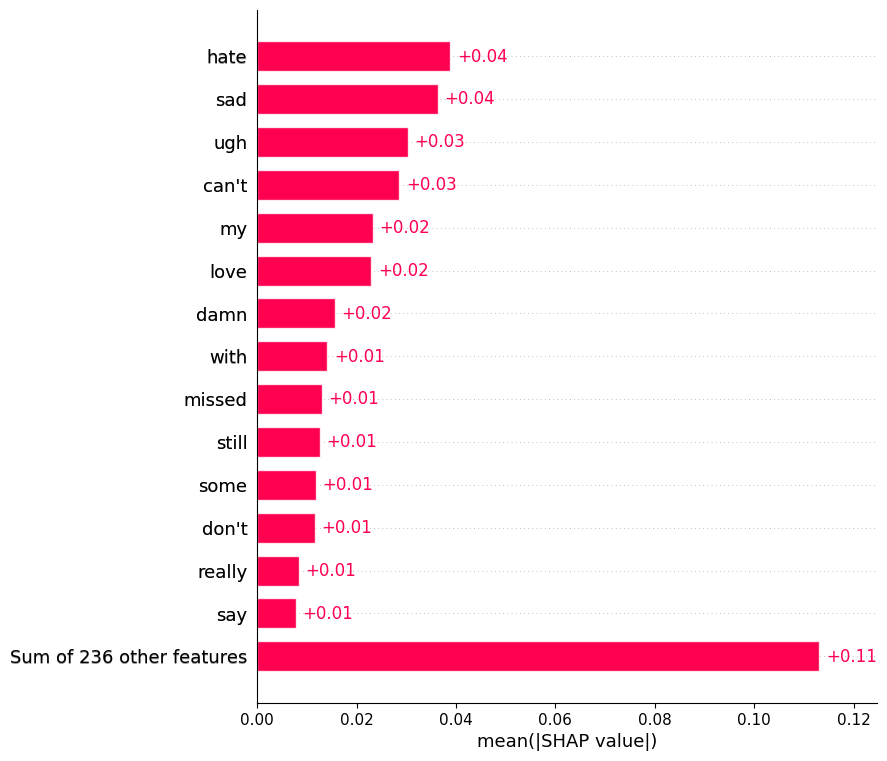

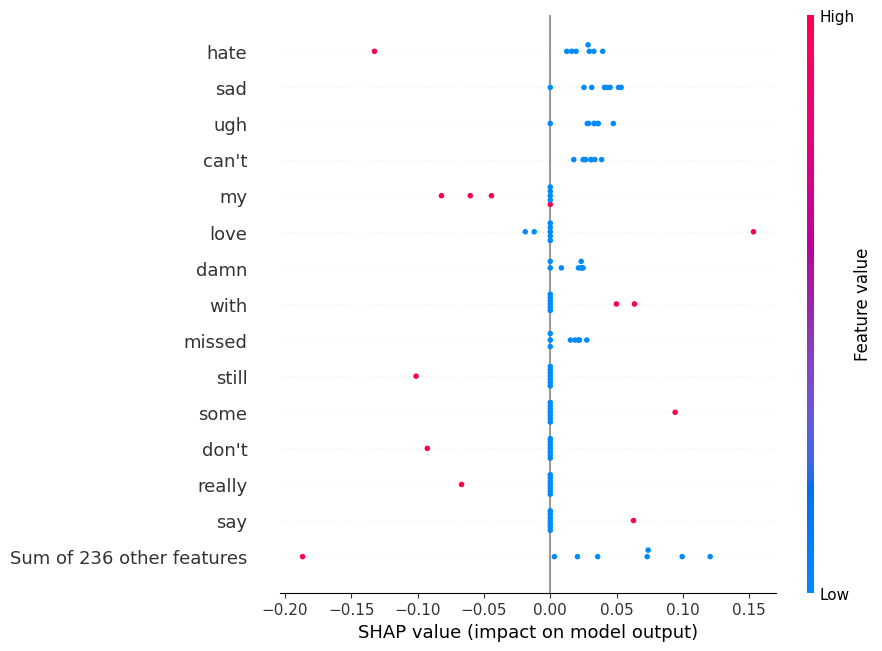

In [9]:
importance = pd.DataFrame({
    "word": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

display(importance.head(15).reset_index(drop=True))
shap.plots.bar(explanation, max_display=15)
shap.plots.beeswarm(explanation, max_display=15)